# 01 - Introduction to APIs and Data Extraction

In [ ]:
import pandas as pd
import requests
from dotenv import load_dotenv
import os
from IPython.display import display, HTML
import json
import matplotlib.pyplot as plt
from io import BytesIO

load_dotenv()
API_KEY = os.getenv("API_KEY")

Matplotlib is building the font cache; this may take a moment.


# Lesson Objectives & Outcomes
By the end of this lesson, you will be able to retrieve data from a REST API, understand JSON responses, and convert API data into a Pandas DataFrame.

--- 

## Imagine You Are a Data Engineer

Your company wants to know the current exchange rates every day. **€ -> $**

You need to collect currency data automatically and make it available for analysis.

**How can you do this without manually downloading the data or without manually checking a website and writing that in your note?**

Today, we will solve this problem using an API and Python.

---

![API](images/1_Of8IMp_IUWq-weo6bxat3A.png)

---

## How Does an API Work?

An API is a way for applications to communicate with each other.

A client sends a request to a server.

The server processes the request and returns a response.

In our example:

- Python is our client.
- Frankfurter is our API.
- The API returns currency exchange rates.
- We use the received data in Python.

---

# FROM YOUR EXPERIENCE
You downloaded a CSV from Kaggle at some point, but if the dataset gets updated, will you download it again? You have a more easily way it's **use API**

all services communicate with each other using the API because it is convenient.

In [ ]:
url = "https://www.kaggle.com/api/v1/datasets/download/johnsmith88/heart-disease-dataset/heart.csv"

headers = {
    "Accept": "file",
    "User-Agent": "Swagger-Codegen/1/python"
}

response = requests.get(url, headers=headers)
response.raise_for_status()

df = pd.read_csv(BytesIO(response.content))
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1


---

# ANOTHER EXAMPLE

In [95]:
url = "https://api.frankfurter.dev/v2/rates"

params = {
    "base": "EUR",
    "quotes": "USD",
    "from": "2026-10-01",
    "to": "2026-11-06"
}

response = requests.get(url, params=params)

In [96]:
response

<Response [200]>

In [97]:
response.text

'[{"date":"2026-10-01","base":"EUR","quote":"USD","rate":1.1326},{"date":"2026-10-02","base":"EUR","quote":"USD","rate":1.1287},{"date":"2026-10-03","base":"EUR","quote":"USD","rate":1.1281},{"date":"2026-10-04","base":"EUR","quote":"USD","rate":1.1277},{"date":"2026-10-05","base":"EUR","quote":"USD","rate":1.1229},{"date":"2026-10-06","base":"EUR","quote":"USD","rate":1.1236},{"date":"2026-10-07","base":"EUR","quote":"USD","rate":1.123},{"date":"2026-10-08","base":"EUR","quote":"USD","rate":1.1203},{"date":"2026-10-09","base":"EUR","quote":"USD","rate":1.1217},{"date":"2026-10-10","base":"EUR","quote":"USD","rate":1.1219},{"date":"2026-10-11","base":"EUR","quote":"USD","rate":1.1219},{"date":"2026-10-12","base":"EUR","quote":"USD","rate":1.1202},{"date":"2026-10-13","base":"EUR","quote":"USD","rate":1.1196},{"date":"2026-10-14","base":"EUR","quote":"USD","rate":1.1198},{"date":"2026-10-15","base":"EUR","quote":"USD","rate":1.1201},{"date":"2026-10-16","base":"EUR","quote":"USD","rate"

## What Is JSON?

**JSON (JavaScript Object Notation)** is a text format used to store and exchange data between applications. APIs often return data in JSON because it is lightweight, readable, and easy for programs to process.

JSON supports a few basic data types:

- **Object** — a collection of key-value pairs, written with `{}`.
- **Array** — an ordered list of values, written with `[]`.
- **String** — text in double quotes.
- **Number** — an integer or decimal number.
- **Boolean** — `true` or `false`.
- **Null** — represents an empty or missing value.

### Example

```json
{
    "date": "2026-11-06",
    "base": "EUR",
    "quote": "USD",
    "rate": 1.16
}
```

In this example, `date`, `base`, `quote`, and `rate` are **keys**, while the values describe the exchange rate.

In [98]:
data = response.json()
display(HTML(f"""
<pre style="font-size: 14px; line-height: 1.5;">
{json.dumps(data[:3], indent=4, ensure_ascii=False)}
</pre>
"""))

In [99]:
df = pd.DataFrame(data)

In [100]:
df

,date,base,quote,rate
0,2026-10-01,EUR,USD,1.1326
1,2026-10-02,EUR,USD,1.1287
2,2026-10-03,EUR,USD,1.1281
3,2026-10-04,EUR,USD,1.1277
4,2026-10-05,EUR,USD,1.1229
5,2026-10-06,EUR,USD,1.1236
6,2026-10-07,EUR,USD,1.1230
7,2026-10-08,EUR,USD,1.1203
8,2026-10-09,EUR,USD,1.1217
9,2026-10-10,EUR,USD,1.1219


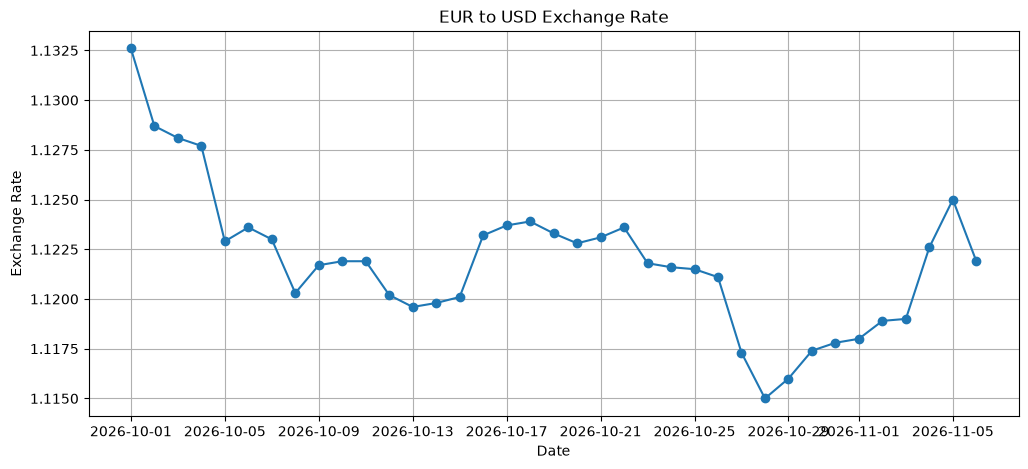

In [101]:
df["date"] = pd.to_datetime(df["date"])

plt.figure(figsize=(12, 5))

plt.plot(
    df["date"],
    df["rate"],
    marker="o"
)

plt.title("EUR to USD Exchange Rate")
plt.xlabel("Date")
plt.ylabel("Exchange Rate")

plt.grid()
plt.show()

---

# Homework: Explore an API and Visualize Its Data

## Goal

Practice the complete data extraction workflow:

**API → Request → JSON → Pandas DataFrame → Visualization**

## Task

Use another API and write code that retrieves data and visualizes it.

## Questions to Answer

- What is JSON, and why do APIs often return data in this format?
- What is the difference between `response.text` and `response.json()`?
- What does `pd.DataFrame(data)` do?
- What does `response.raise_for_status()` help us check?

## Learn
- What other types of APIs exist, and why are they needed?
- What other methods of REST API exist, and why are they needed?